# [title] Two-state Model: the Simulator and the Prior

**Question.** Do `simulate_sitting` and `sample_prior` produce what
[decision 0008](../../docs/decisions/0008-two-state-model.md) says, and do the Sittings
they lead to look like those of real experiments? Terms: [glossary](../../docs/glossary.md).

**Scope.** The second pull request of
[#28](https://github.com/opherdonchin/MotorAdpatationSBI/issues/28). The Model is written
up in [docs/models/two_state.md](../../docs/models/two_state.md); the code is in
[`src/models/two_state.py`](../../src/models/two_state.py). The cells follow the two
one-state working notebooks (the Simulator's and the Prior's), with the two-state Model.

**Checks:**

1. *The link to the one-state Model.* When the two retentions are equal, the movements
   are those of the one-state Model with adaptation rate $B_f + B_s$ and planning noise
   $\sqrt 2\,\sigma_\eta$: exactly without noise, and in their steady-state statistics
   with noise.
2. *It behaves like a two-state model.* Without noise the states follow the closed-form
   solution of the two linear recursions, and after a short reversal the movement
   recovers spontaneously. With noise, the steady-state standard deviation and lag-1
   correlation match those computed from the Model by linear algebra.
3. *The Prior.* Each quantity's central 95% interval is the one in the decision's table;
   then simulated Sittings, for Opher to judge by eye.

In [1]:
# [imports]
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import linalg, special, stats

from designs import visuomotor_adaptation_experiment as des
from models import one_state
from models import two_state as mdl

In [2]:
# [config] Root seed, example Sitting, Prior and Schedule Design constants, sizes of the Checks
root_seed = 15076981454491607406712533078155144610  # secrets.randbits(128)

# theta = (A_fast, A_slow, B_fast, B_slow, sigma_eta, sigma_epsilon), in units of the
# perturbation size. The four rates are those of Smith et al. (2006).
theta_example = (0.59, 0.992, 0.21, 0.02, 0.02, 0.15)
example_blocks = [("baseline", 40), ("+1", 200), ("-1", 12), ("no vision", 60), ("baseline", 40)]
tiny = 1e-12  # noise standard deviation that makes a Sitting deterministic

# Check 1: one retention for both states, and the two adaptation rates.
equal_A, equal_B_fast, equal_B_slow = 0.95, 0.15, 0.05

# Parameter sets for the steady-state Checks. The first has (nearly) equal retentions,
# so the one-state formulas apply to it as well.
stationary_thetas = [
    (equal_A, np.nextafter(equal_A, 1), equal_B_fast, equal_B_slow, 0.03, 0.15),
    (0.59, 0.992, 0.21, 0.02, 0.02, 0.15),
    (0.8, 0.98, 0.3, 0.05, 0.03, 0.1),
    (0.4, 0.995, 0.1, 0.01, 0.01, 0.2),
]
n_sittings = 2000  # independent Sittings per parameter set and condition
t_burn = 1500  # Trials discarded first, until the start no longer matters
t_keep = 800  # Trials kept per Sitting for the statistics
n_batches = 20  # groups of Sittings, for the Monte Carlo standard errors

# Decision 0008: each part of the Prior is normal on an unbounded scale, and the stated
# range is its central 95% interval.
range_A_fast = (0.30, 0.95)
range_A_diff = (1.5, 7.0)  # logit(A_slow) - logit(A_fast)
range_B_fast = (0.05, 0.60)
range_B_diff = (0.7, 5.0)  # logit(B_fast) - logit(B_slow)
range_sigma_epsilon = (1 / 15, 1 / 3)
range_ratio = (1 / 15, 1 / 5)  # sigma_eta / sigma_epsilon
range_block_len = (10, 250)  # trials

z95 = stats.norm.ppf(0.975)
prior = {
    "mu_logit_A_fast": special.logit(range_A_fast).mean(), "sigma_logit_A_fast": np.ptp(special.logit(range_A_fast)) / (2 * z95),
    "mu_log_A_diff": np.log(range_A_diff).mean(), "sigma_log_A_diff": np.ptp(np.log(range_A_diff)) / (2 * z95),
    "mu_logit_B_fast": special.logit(range_B_fast).mean(), "sigma_logit_B_fast": np.ptp(special.logit(range_B_fast)) / (2 * z95),
    "mu_log_B_diff": np.log(range_B_diff).mean(), "sigma_log_B_diff": np.ptp(np.log(range_B_diff)) / (2 * z95),
    "mu_log_sigma_epsilon": np.log(range_sigma_epsilon).mean(),
    "sigma_log_sigma_epsilon": np.ptp(np.log(range_sigma_epsilon)) / (2 * z95),
    "mu_log_ratio": np.log(range_ratio).mean(), "sigma_log_ratio": np.ptp(np.log(range_ratio)) / (2 * z95),
}
schedule_design = {
    "n_blocks_min": 5, "n_blocks_max": 16,
    "mu_log_block_len": np.log(range_block_len).mean(),
    "sigma_log_block_len": np.ptp(np.log(range_block_len)) / (2 * z95),
    "trial_type_concentration": 3.0,
}

n_prior_draws = 1_000_000  # enough to count unstable draws, about 13 per million
n_examples = 9  # simulated Sittings shown

pd.Series({**prior, **schedule_design}).round(3)

mu_logit_A_fast              1.049
sigma_logit_A_fast           0.967
mu_log_A_diff                1.176
sigma_log_A_diff             0.393
mu_logit_B_fast             -1.269
sigma_logit_B_fast           0.855
mu_log_B_diff                0.626
sigma_log_B_diff             0.502
mu_log_sigma_epsilon        -1.903
sigma_log_sigma_epsilon      0.411
mu_log_ratio                -2.159
sigma_log_ratio              0.280
n_blocks_min                 5.000
n_blocks_max                16.000
mu_log_block_len             3.912
sigma_log_block_len          0.821
trial_type_concentration     3.000
dtype: float64

In [3]:
# [rng] One root generator, one stream per purpose
rng = np.random.default_rng(root_seed)
rng_example, rng_equal, rng_stationary, rng_prior, rng_generated = rng.spawn(5)

In [4]:
# [plot-style] Colours and axes shared by the figures
blue, orange, green, muted, grid, shade = "#2a78d6", "#d9822b", "#3a9a5c", "#898781", "#e1e0d9", "#f0efec"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": muted, "axes.labelcolor": "#52514e",
    "xtick.color": muted, "ytick.color": muted,
    "axes.titlesize": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "figure.constrained_layout.use": True,
})

## [model] The Model

$$
x^f_{t+1} = A_f\, x^f_t - B_f\, v_t\, e_t + \eta^f_t, \qquad
x^s_{t+1} = A_s\, x^s_t - B_s\, v_t\, e_t + \eta^s_t
$$

$$
y_t = x^f_t + x^s_t + \varepsilon_t, \qquad e_t = y_t + p_t
$$

$x^f_t$ and $x^s_t$ are the fast and the slow part of the plan, $y_t$ the movement, $p_t$
the perturbation, $e_t$ the error and $v_t$ the vision flag. Both states learn from the
same error. $\eta^f_t$ and $\eta^s_t$ are independent, each with standard deviation
$\sigma_\eta$; $\varepsilon_t$ has standard deviation $\sigma_\varepsilon$; each state
starts from a draw with standard deviation $\sigma_\eta$.

`simulate_sitting(rng, theta, schedule, size)` runs these equations forward for `size`
Sittings at once. It returns the Observations (`y`) and, separately, the Ground Truth
(the parameter values and the states `x_fast` and `x_slow`).

In [5]:
# [example-schedule] A hand-made Schedule: adaptation, a short reversal, then no vision
lengths = [n for _, n in example_blocks]
schedule = {
    name: np.repeat([des.TRIAL_TYPES[trial_type][name] for trial_type, _ in example_blocks], lengths)
    for name in ("p", "v")
}
p, v = schedule["p"], schedule["v"]
trial = np.arange(1, len(p) + 1)

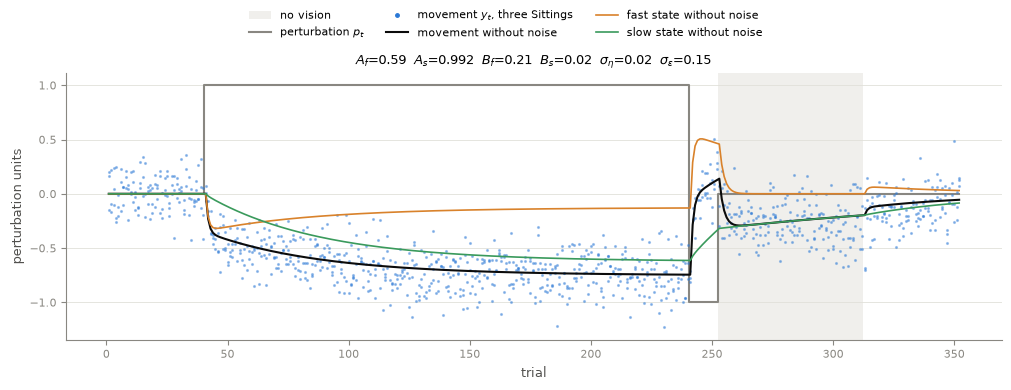

In [6]:
# [example-sittings] Three simulated Sittings, and the noise-free movement and states
theta_clean = (*theta_example[:4], tiny, tiny)
y_noisy = mdl.simulate_sitting(rng_example, theta_example, schedule, size=(3,))[0]["y"]
observations_clean, truth_clean = mdl.simulate_sitting(rng_example, theta_clean, schedule)
y_clean, x_fast_clean, x_slow_clean = observations_clean["y"], truth_clean["x_fast"], truth_clean["x_slow"]

fig, ax = plt.subplots(figsize=(10, 3.8))
for start, stop in np.nonzero(np.diff(np.r_[1, v, 1]) != 0)[0].reshape(-1, 2):
    ax.axvspan(start + 0.5, stop + 0.5, color=shade, lw=0, label="no vision")
ax.step(trial, p, where="mid", color=muted, lw=1.5, label="perturbation $p_t$")
ax.plot(trial, y_noisy.T, ".", color=blue, ms=2.5, alpha=0.4)
ax.plot([], [], ".", color=blue, ms=5, label="movement $y_t$, three Sittings")
ax.plot(trial, y_clean, color="#0b0b0b", lw=1.5, label="movement without noise")
ax.plot(trial, x_fast_clean, color=orange, lw=1.2, label="fast state without noise")
ax.plot(trial, x_slow_clean, color=green, lw=1.2, label="slow state without noise")
ax.set_xlabel("trial")
ax.set_ylabel("perturbation units")
ax.set_title("$A_f$={}  $A_s$={}  $B_f$={}  $B_s$={}  $\\sigma_\\eta$={}  $\\sigma_\\varepsilon$={}".format(*theta_example))
ax.grid(axis="y", color=grid, lw=0.6)
fig.legend(loc="outside upper center", frameon=False, fontsize=8, ncols=3)
plt.show()

## [check-1] Check 1: the link to the one-state Model

With one planning noise shared by the two states, neither state can be switched off, so
the one-state Model is not a special case. The link is at the edge of the domain. When
$A_f = A_s = A$, adding the two state equations gives

$$
x_{t+1} = A\, x_t - (B_f + B_s)\, v_t\, e_t + (\eta^f_t + \eta^s_t), \qquad x_t = x^f_t + x^s_t
$$

which is the one-state Model with adaptation rate $B_f + B_s$ and planning noise
$\sqrt 2\,\sigma_\eta$. The Simulator requires $A_f$ below $A_s$, so $A_s$ is set to the
next number above $A$ that the computer can represent.

Without noise the two Simulators must then give the same movements. With noise they use
their random numbers differently, so the comparison is of steady-state statistics, in
`[check-stationary]` below (its first row).

In [7]:
# [check-equal-retention] Noise-free movements: two-state with equal retentions against one-state
theta_two = (equal_A, np.nextafter(equal_A, 1), equal_B_fast, equal_B_slow, tiny, tiny)
theta_one = (equal_A, equal_B_fast + equal_B_slow, tiny, tiny)
y_two = mdl.simulate_sitting(rng_equal, theta_two, schedule)[0]["y"]
y_one = one_state.simulate_sitting(rng_equal, theta_one, schedule)[0]["y"]

max_abs_diff_equal = np.abs(y_two - y_one).max()
assert max_abs_diff_equal < 1e-9
print(f"largest difference between the two Simulators: {max_abs_diff_equal:.1e}")

largest difference between the two Simulators: 1.4e-11


## [check-2] Check 2: it behaves like a two-state model

**Without noise.** Write $s_t = (x^f_t, x^s_t)$ and $b = (B_f, B_s)$. Within a Block,
with vision and perturbation $p$,

$$
s_{t+1} = S\, s_t - b\, p, \qquad
S = \begin{pmatrix} A_f - B_f & -B_f \\ -B_s & A_s - B_s \end{pmatrix}
$$

so $s_t = s^* + S^{\,t}(s_0 - s^*)$ with fixed point $s^* = -(I - S)^{-1} b\, p$. Without
vision $S$ is the diagonal matrix of the two retentions and nothing is added. The
closed form is computed Block by Block, each Block starting where the last one ended,
and compared with the Simulator run with negligible noise.

**Spontaneous recovery.** In the example Schedule the short reversal brings the movement
back toward zero mostly by pushing the fast state the other way, while the slow state
still holds most of the first adaptation. In the no-vision Block the fast state decays
within a few Trials and the movement returns toward the first adaptation before it
decays slowly (Smith et al. 2006). The Check is that the movement goes further from
zero, on the side of the first adaptation, after the no-vision Block starts.

In [8]:
# [check-noise-free] Closed-form states, Block by Block, against the noise-free simulation
A_fast, A_slow, B_fast, B_slow = theta_example[:4]
b = np.array([B_fast, B_slow])
closed_form = []
s_start = np.zeros(2)  # both states start at 0 without noise
for trial_type, n in example_blocks:
    p_block, v_block = des.TRIAL_TYPES[trial_type]["p"], des.TRIAL_TYPES[trial_type]["v"]
    step = np.diag([A_fast, A_slow]) - v_block * np.outer(b, np.ones(2))
    s_star = -np.linalg.solve(np.eye(2) - step, b) * p_block * v_block
    curve = np.array([s_star + np.linalg.matrix_power(step, k) @ (s_start - s_star) for k in range(n + 1)])
    closed_form.append(curve[:-1])  # the Block's n Trials
    s_start = curve[-1]  # the first Trial of the next Block
closed_form = np.concatenate(closed_form)

max_abs_diff_states = max(
    np.abs(closed_form[:, 0] - x_fast_clean).max(), np.abs(closed_form[:, 1] - x_slow_clean).max()
)
assert max_abs_diff_states < 1e-9
print(f"largest difference between closed form and simulation: {max_abs_diff_states:.1e}")

largest difference between closed form and simulation: 1.1e-11


In [9]:
# [check-spontaneous-recovery] The movement at the start of the no-vision Block and at its furthest
first_no_vision = int(np.nonzero(v == 0)[0][0])
y_no_vision = y_clean[v == 0]
recovery = pd.Series({
    "movement at the end of the first adaptation": y_clean[np.nonzero(p == -1)[0][0] - 1],
    "movement on the first no-vision Trial": y_no_vision[0],
    "furthest movement in the no-vision Block": y_no_vision.min(),
    "Trials into the Block when it is reached": int(y_no_vision.argmin()),
    "fast state on the first no-vision Trial": x_fast_clean[first_no_vision],
    "slow state on the first no-vision Trial": x_slow_clean[first_no_vision],
})
assert y_no_vision.min() < y_no_vision[0] - 0.1
recovery.round(3)

movement at the end of the first adaptation   -0.745
movement on the first no-vision Trial          0.139
furthest movement in the no-vision Block      -0.292
Trials into the Block when it is reached       9.000
fast state on the first no-vision Trial        0.458
slow state on the first no-vision Trial       -0.319
dtype: float64

**With noise.** Under a constant perturbation the two states settle into a stationary
fluctuation around the fixed point. With vision, $s_{t+1} - s^* = S\,(s_t - s^*) - b\,\varepsilon_t + \eta_t$,
so the covariance matrix $P$ of the states solves

$$
P = S\, P\, S^\top + \sigma_\varepsilon^2\, b\, b^\top + \sigma_\eta^2\, I
$$

and, with $\mathbf 1 = (1, 1)$,

$$
\sigma_y^2 = \mathbf 1^\top P\, \mathbf 1 + \sigma_\varepsilon^2, \qquad
R(1) = \frac{\mathbf 1^\top S\, P\, \mathbf 1 - \sigma_\varepsilon^2\, \mathbf 1^\top b}{\sigma_y^2}
$$

Without vision the same holds with $b = 0$ and $S$ the diagonal matrix of the
retentions. $P$ is computed by `scipy.linalg.solve_discrete_lyapunov`, which shares no
code with the Simulator. For the first parameter set, whose retentions are equal, the
one-state formulas of [docs/models/one_state.md](../../docs/models/one_state.md) are
computed as well, with $B = B_f + B_s$ and planning noise $\sqrt 2\,\sigma_\eta$.

For each parameter set, `n_sittings` Sittings are simulated under $p = 0$, with vision
and without. The first `t_burn` Trials are discarded; the standard deviation and the
lag-1 correlation are computed from the rest. Standard errors come from the spread
between `n_batches` groups of Sittings.

In [10]:
# [check-stationary] Simulated steady-state statistics against the linear-algebra values
rows = []
for theta in stationary_thetas:
    A_f, A_s, B_f, B_s, s_eta, s_eps = theta
    for vision in (1, 0):
        T = t_burn + t_keep
        schedule_flat = {"p": np.zeros(T), "v": np.full(T, vision)}
        y = mdl.simulate_sitting(rng_stationary, theta, schedule_flat, size=(n_sittings,))[0]["y"]
        batches = y[:, t_burn:].reshape(n_batches, -1, t_keep)
        sd = batches.std(axis=(1, 2))
        r1 = np.array([np.corrcoef(batch[:, :-1].ravel(), batch[:, 1:].ravel())[0, 1] for batch in batches])

        b = vision * np.array([B_f, B_s])
        step = np.diag([A_f, A_s]) - np.outer(b, np.ones(2))
        P = linalg.solve_discrete_lyapunov(step, s_eps**2 * np.outer(b, b) + s_eta**2 * np.eye(2))
        var_y = P.sum() + s_eps**2
        r1_expected = ((step @ P).sum() - s_eps**2 * b.sum()) / var_y

        if A_s - A_f < 1e-9:  # equal retentions: the one-state formulas apply
            A_one, B_one, s_eta_one = A_f, vision * (B_f + B_s), np.sqrt(2) * s_eta
            var_x = (s_eta_one**2 + B_one**2 * s_eps**2) / (1 - (A_one - B_one) ** 2)
            sd_one_state = np.sqrt(s_eps**2 + var_x)
            r1_one_state = ((A_one - B_one) * var_x - B_one * s_eps**2) / (s_eps**2 + var_x)
        else:
            sd_one_state = r1_one_state = np.nan

        se_sd, se_r1 = sd.std(ddof=1) / np.sqrt(n_batches), r1.std(ddof=1) / np.sqrt(n_batches)
        rows.append({
            "theta": tuple(round(float(value), 3) for value in theta),
            "vision": bool(vision),
            "sd simulated": sd.mean(),
            "sd expected": np.sqrt(var_y),
            "sd z": (sd.mean() - np.sqrt(var_y)) / se_sd,
            "R1 simulated": r1.mean(),
            "R1 expected": r1_expected,
            "R1 z": (r1.mean() - r1_expected) / se_r1,
            "sd one-state formula": sd_one_state,
            "R1 one-state formula": r1_one_state,
        })
check_stationary = pd.DataFrame(rows)
print("largest z-score in size:", check_stationary[["sd z", "R1 z"]].abs().max().max().round(2))
check_stationary.round(4)

largest z-score in size: 2.0


,theta,vision,sd simulated,sd expected,sd z,R1 simulated,R1 expected,R1 z,sd one-state formula,R1 one-state formula
0,"(0.95, 0.95, 0.15, 0.05, 0.03, 0.15)",True,0.1692,0.1693,-1.4693,0.0033,0.0045,-1.8106,0.1693,0.0045
1,"(0.95, 0.95, 0.15, 0.05, 0.03, 0.15)",False,0.2025,0.2024,0.2790,0.4281,0.4282,-0.0707,0.2024,0.4282
2,"(0.59, 0.992, 0.21, 0.02, 0.02, 0.15)",True,0.1694,0.1695,-1.0928,-0.0106,-0.0105,-0.0757,NaN,NaN
3,"(0.59, 0.992, 0.21, 0.02, 0.02, 0.15)",False,0.2195,0.2196,-0.0561,0.5237,0.5239,-0.0691,NaN,NaN
4,"(0.8, 0.98, 0.3, 0.05, 0.03, 0.1)",True,0.1236,0.1236,-0.0951,-0.0137,-0.0133,-0.3788,NaN,NaN
5,"(0.8, 0.98, 0.3, 0.05, 0.03, 0.1)",False,0.1880,0.1877,0.5071,0.6897,0.6890,0.4145,NaN,NaN
6,"(0.4, 0.995, 0.1, 0.01, 0.01, 0.2)",True,0.2086,0.2085,0.8838,-0.0336,-0.0324,-1.3154,NaN,NaN
7,"(0.4, 0.995, 0.1, 0.01, 0.01, 0.2)",False,0.2233,0.2239,-1.9955,0.1963,0.1999,-1.7583,NaN,NaN


## [check-3] Check 3: the Prior

`sample_prior` draws $\mathrm{logit}(A_f)$, $\log d_A$, $\mathrm{logit}(B_f)$, $\log d_B$,
$\log\sigma_\varepsilon$ and $\log(\sigma_\eta/\sigma_\varepsilon)$ from independent
normals, where $d_A = \mathrm{logit}(A_s) - \mathrm{logit}(A_f)$ and
$d_B = \mathrm{logit}(B_f) - \mathrm{logit}(B_s)$ are positive, and draws again when the
result is unstable. The 2.5% and 97.5% quantiles of each of these six quantities must be
the ends of its stated range. The slow state's rates, the time constants and the
adaptation reached under a constant perturbation have no range of their own; their
intervals are what the Prior implies.

Under a constant perturbation $p$ with vision and no noise, the movement settles at
$-p\,K/(1+K)$ with $K = B_f/(1-A_f) + B_s/(1-A_s)$, and the slow state holds the share
$\big(B_s/(1-A_s)\big)/K$ of it.

In [11]:
# [check-prior-ranges] Quantiles of the drawn quantities against the stated ranges
theta = mdl.sample_prior(rng_prior, n_prior_draws, prior)
A_fast, A_slow, B_fast, B_slow, sigma_eta, sigma_epsilon = theta.T
K = B_fast / (1 - A_fast) + B_slow / (1 - A_slow)
drawn = {
    "A_fast": A_fast, "A_diff": special.logit(A_slow) - special.logit(A_fast),
    "B_fast": B_fast, "B_diff": special.logit(B_fast) - special.logit(B_slow),
    "sigma_epsilon": sigma_epsilon, "ratio": sigma_eta / sigma_epsilon,
    "A_slow": A_slow, "B_slow": B_slow, "sigma_eta": sigma_eta,
    "fast time constant (trials)": -1 / np.log(A_fast),
    "slow time constant (trials)": -1 / np.log(A_slow),
    "adaptation reached (fraction of p)": K / (1 + K),
    "slow state's share of it": B_slow / (1 - A_slow) / K,
}
stated = {
    "A_fast": range_A_fast, "A_diff": range_A_diff, "B_fast": range_B_fast, "B_diff": range_B_diff,
    "sigma_epsilon": range_sigma_epsilon, "ratio": range_ratio,
}
assert np.all((A_fast < A_slow) & (B_fast > B_slow))
assert np.all(B_fast / (1 + A_fast) + B_slow / (1 + A_slow) < 1)
pd.DataFrame({
    name: {
        "stated 2.5%": stated.get(name, (np.nan, np.nan))[0],
        "drawn 2.5%": np.quantile(x, 0.025),
        "drawn median": np.median(x),
        "stated 97.5%": stated.get(name, (np.nan, np.nan))[1],
        "drawn 97.5%": np.quantile(x, 0.975),
    }
    for name, x in drawn.items()
}).T.round(4)

,stated 2.5%,drawn 2.5%,drawn median,stated 97.5%,drawn 97.5%
A_fast,0.3000,0.3002,0.7407,0.9500,0.9500
A_diff,1.5000,1.4990,3.2407,7.0000,7.0071
B_fast,0.0500,0.0500,0.2192,0.6000,0.5994
B_diff,0.7000,0.6990,1.8701,5.0000,4.9964
sigma_epsilon,0.0667,0.0669,0.1491,0.3333,0.3333
ratio,0.0667,0.0667,0.1155,0.2000,0.2004
A_slow,NaN,0.8399,0.9876,NaN,0.9998
B_slow,NaN,0.0013,0.0375,NaN,0.2600
sigma_eta,NaN,0.0065,0.0172,NaN,0.0456
fast time constant (trials),NaN,0.8311,3.3311,NaN,19.5147


In [12]:
# [unstable-draws] How often the untruncated Prior gives an unstable Model
# Drawn here directly from the six normals, without the redraw, to count what it removes.
rng_count = rng_prior.spawn(1)[0]
logit_A_fast = rng_count.normal(prior["mu_logit_A_fast"], prior["sigma_logit_A_fast"], n_prior_draws)
logit_B_fast = rng_count.normal(prior["mu_logit_B_fast"], prior["sigma_logit_B_fast"], n_prior_draws)
A_diff = np.exp(rng_count.normal(prior["mu_log_A_diff"], prior["sigma_log_A_diff"], n_prior_draws))
B_diff = np.exp(rng_count.normal(prior["mu_log_B_diff"], prior["sigma_log_B_diff"], n_prior_draws))
unstable = (
    special.expit(logit_B_fast) / (1 + special.expit(logit_A_fast))
    + special.expit(logit_B_fast - B_diff) / (1 + special.expit(logit_A_fast + A_diff))
) >= 1
print(f"unstable draws: {unstable.sum()} of {n_prior_draws:,}")

unstable draws: 12 of 1,000,000


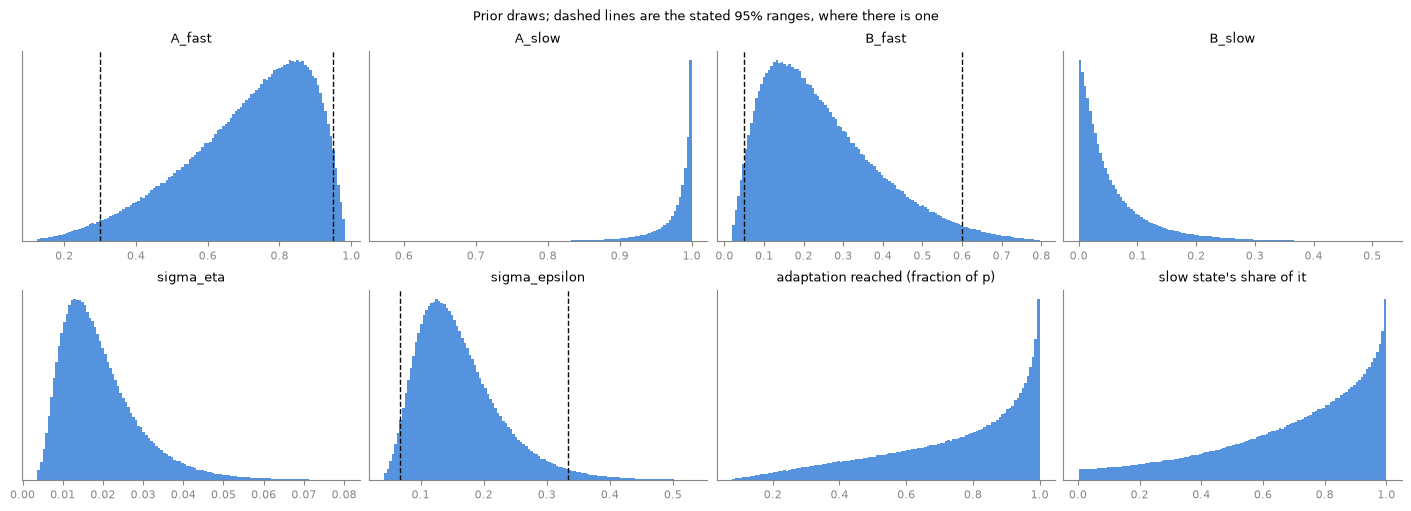

In [13]:
# [prior-histograms] What the Prior looks like on the natural scale
shown = ["A_fast", "A_slow", "B_fast", "B_slow", "sigma_eta", "sigma_epsilon",
         "adaptation reached (fraction of p)", "slow state's share of it"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, name in zip(axes.flat, shown):
    x = drawn[name]
    ax.hist(x, bins=120, range=tuple(np.quantile(x, [0.001, 0.999])), color=blue, alpha=0.8)
    for edge in stated.get(name, ()):
        ax.axvline(edge, color="#0b0b0b", lw=1, ls="--")
    ax.set_title(name)
    ax.set_yticks([])
fig.suptitle("Prior draws; dashed lines are the stated 95% ranges, where there is one", fontsize=9)
plt.show()

**Simulated Sittings.** Each panel is one Sitting: its own Schedule from the Schedule
Design of the one-state Model, its own parameter values drawn from the Prior, and the
movements the Simulator produces. Grey bands are no-vision Blocks; the grey line is the
perturbation; dots are movements; the orange and green lines are the fast and slow
states (Ground Truth). A learner compensates by moving to $-p$.

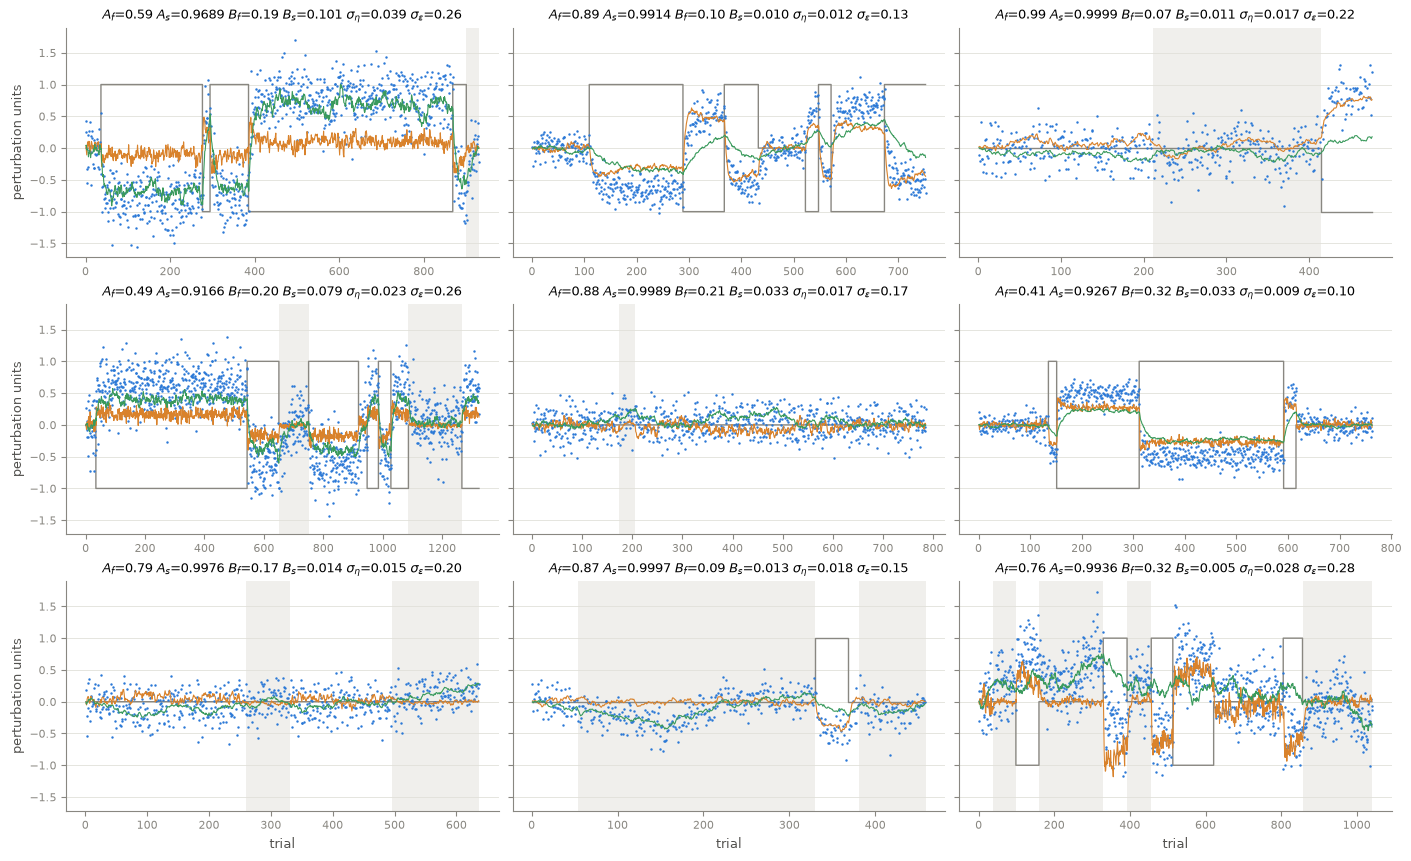

In [14]:
# [generated-sittings] Sittings from the Prior Sampler, the Schedule Generator and the Simulator
thetas = mdl.sample_prior(rng_generated, n_examples, prior)
fig, axes = plt.subplots(3, 3, figsize=(14, 8.5), sharey=True)
for ax, th in zip(axes.flat, thetas):
    schedule_drawn = des.sample_schedule(rng_generated, schedule_design)
    p_drawn, v_drawn = schedule_drawn["p"], schedule_drawn["v"]
    observations, truth = mdl.simulate_sitting(rng_generated, th, schedule_drawn)
    trial_drawn = np.arange(1, len(p_drawn) + 1)
    for start, stop in np.nonzero(np.diff(np.r_[1, v_drawn, 1]) != 0)[0].reshape(-1, 2):
        ax.axvspan(start + 0.5, stop + 0.5, color=shade, lw=0)
    ax.step(trial_drawn, p_drawn, where="mid", color=muted, lw=1)
    ax.plot(trial_drawn, observations["y"], ".", color=blue, ms=1.5)
    ax.plot(trial_drawn, truth["x_fast"], color=orange, lw=0.8)
    ax.plot(trial_drawn, truth["x_slow"], color=green, lw=0.8)
    ax.set_title(
        "$A_f$={:.2f} $A_s$={:.4f} $B_f$={:.2f} $B_s$={:.3f} "
        "$\\sigma_\\eta$={:.3f} $\\sigma_\\varepsilon$={:.2f}".format(*th)
    )
    ax.grid(axis="y", color=grid, lw=0.6)
for ax in axes[-1]:
    ax.set_xlabel("trial")
for ax in axes[:, 0]:
    ax.set_ylabel("perturbation units")
plt.show()

## [results] What this shows

1. **The link to the one-state Model: pass.** With equal retentions and no noise, the
   two Simulators differ by at most $1.4 \times 10^{-11}$ over the example Schedule
   (`[check-equal-retention]`). With noise, the two-state steady-state values for that
   parameter set are the one-state formulas' values to four decimals (standard
   deviation 0.1693 with vision and 0.2024 without; lag-1 correlation 0.0045 and
   0.4282), and the simulation agrees with both (first two rows of `[check-stationary]`).
2. **It behaves like a two-state model: pass.**
   - Without noise, the simulated states and the closed form differ by at most
     $1.1 \times 10^{-11}$ through all five Blocks (`[check-noise-free]`).
   - Spontaneous recovery: after 200 Trials of adaptation (movement $-0.75$) and 12
     Trials of reversal, the movement on the first no-vision Trial is $+0.14$, made of a
     fast state at $+0.46$ and a slow state at $-0.32$. Nine Trials later the movement
     is at $-0.29$: the fast state has decayed and the slow state's adaptation shows
     (`[check-spontaneous-recovery]`; the black line in the grey band of the first
     figure).
   - With noise, for all four parameter sets, with and without vision, the simulated
     standard deviation and lag-1 correlation agree with the linear-algebra values
     within Monte Carlo error: the largest of the 16 z-scores is 2.0 in size
     (`[check-stationary]`).
3. **Prior Sampler: pass.** Over a million draws, the 2.5% and 97.5% quantiles of the
   six quantities that have a stated range match it within sampling error
   (`[check-prior-ranges]`). Every draw is ordered and stable. Without the redraw, 12
   draws in a million are unstable (`[unstable-draws]`).
4. **Simulated Sittings:** for Opher to judge (`[generated-sittings]`).

**What the Prior implies** (`[check-prior-ranges]`), for the quantities that have no
range of their own: slow retention 0.84 to 0.9998 (median 0.988); slow adaptation rate
0.001 to 0.26 (median 0.037); fast time constant 0.8 to 20 Trials; slow time constant 6
to about 4,700 Trials (median 80); adaptation reached under a constant perturbation 23%
to 99.6% of it (median 80%), of which the slow state holds 10% to 99% (median 77%).

**Worth looking at in the simulated Sittings.** In several panels the two states are
hard to tell apart by eye even with the Ground Truth drawn: where the slow retention is
at the low end of its range (0.92 to 0.97) the "slow" state follows each Block within
tens of Trials, and where the fast retention is high (0.99) the "fast" state is slow.
The Prior allows a slow time constant as short as 6 Trials and a fast one as long as 20.
Whether that overlap is wanted is a question about the Prior, for the review of
[decision 0008](../../docs/decisions/0008-two-state-model.md).